In [6]:
import pandas as pd 
import numpy as np
from scipy.stats import chi2_contingency
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

EJERCICIO 1

In [7]:
crosstab_counts = pd.crosstab(df["category"], df["isBestSeller"])
crosstab_prop = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")
crosstab_sorted = crosstab_prop.sort_values(by=True, ascending=False)

print(crosstab_sorted.head(10))

isBestSeller                       False     True 
category                                          
Grocery                         0.941865  0.058135
Smart Home Security & Lighting  0.942308  0.057692
Health & Personal Care          0.942314  0.057686
Mobile Phone Accessories        0.957529  0.042471
Power & Hand Tools              0.964661  0.035339
Billiard, Snooker & Pool        0.967871  0.032129
Pet Supplies                    0.969800  0.030200
Home Brewing & Wine Making      0.971545  0.028455
Mirrors                         0.972000  0.028000
Wind Instruments                0.972000  0.028000


EJERCICIO 2

In [9]:
chi2, p_value, dof, expected = chi2_contingency(crosstab_counts)

print(f"Chi2: {chi2:.2f}")
print(f"p-value: {p_value:.4g}")
print(f"Grados de libertad: {dof}")


Chi2: 36540.20
p-value: 0
Grados de libertad: 295


In [12]:
n = crosstab_counts.to_numpy().sum()    
min_dim = min(crosstab_counts.shape) - 1    
cramers_v = np.sqrt(chi2 / (n * min_dim))

In [13]:
print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.1223


EJERCICIO 3

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

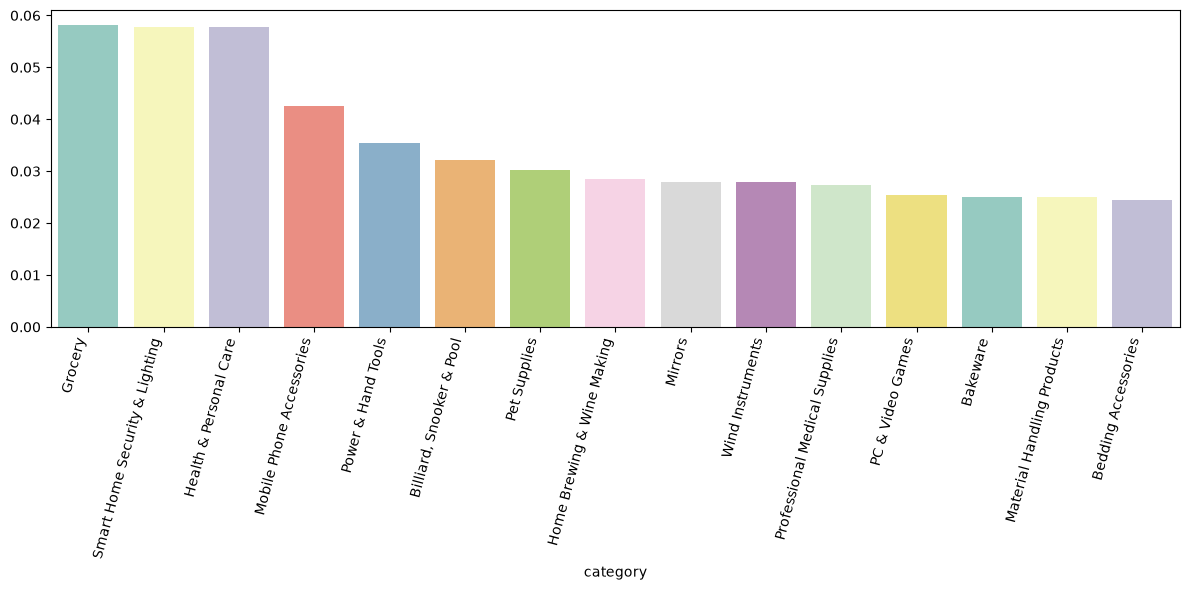

In [19]:
frequency_table = crosstab_sorted[True].head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=frequency_table.index, y=frequency_table.values, hue=frequency_table.index, palette="Set3", legend=False)
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show();

CHALLENGE 2 

EJERCICIO 0

In [20]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

In [21]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

In [22]:

print(f"Filas antes: {len(df)}")
print(f"Filas después: {len(df_no_outliers)}")
print(f"Outliers eliminados: {len(df) - len(df_no_outliers)}")

Filas antes: 2443651
Filas después: 2115963
Outliers eliminados: 327688


EJERCICIO 1

In [23]:
top_20_categories = df_no_outliers["category"].value_counts().head(20).index

df_top20 = df_no_outliers[df_no_outliers["category"].isin(top_20_categories)]

In [24]:
median_prices = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)

print(median_prices.head(10))
print(f"\nCategoría con mayor mediana de precio: {median_prices.index[0]} ({median_prices.iloc[0]:.2f})")

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

Categoría con mayor mediana de precio: Desktop PCs (74.00)


<Axes: xlabel='category', ylabel='price'>

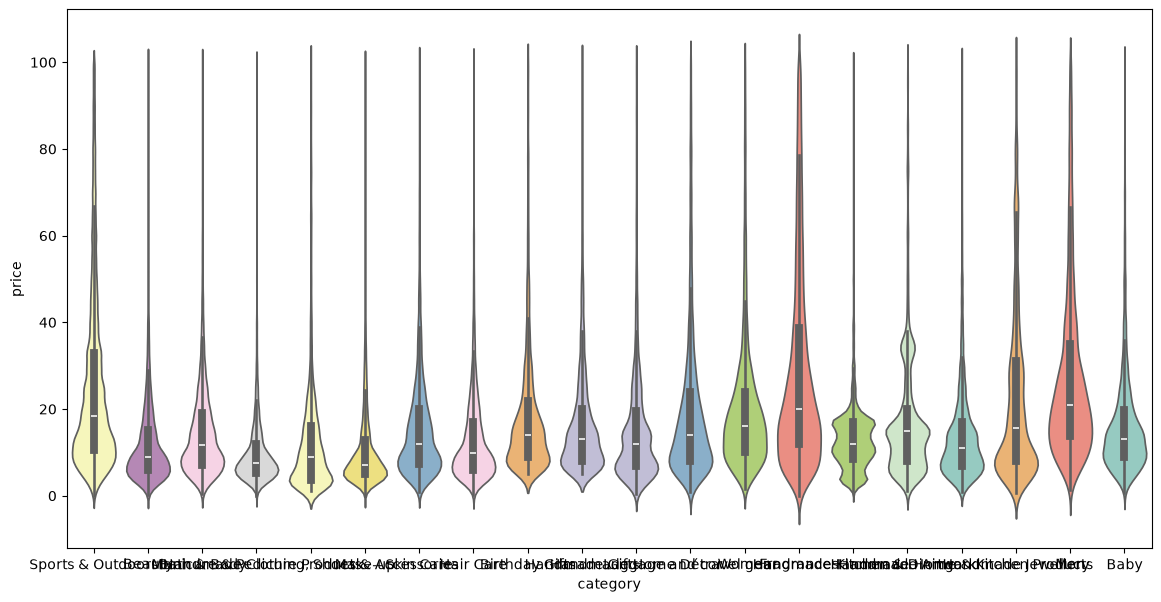

In [25]:
plt.figure(figsize=(14, 7))
sns.violinplot(
    data=df_top20,
    x="category",
    y="price",
    order=top_20_categories,
    hue="category",
    palette="Set3",
    legend=False,
)

EJERCICIO 

C:\Users\walne\AppData\Local\Temp\ipykernel_23912\2471649972.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table.index, y=frequency_table.values, palette="Set3");


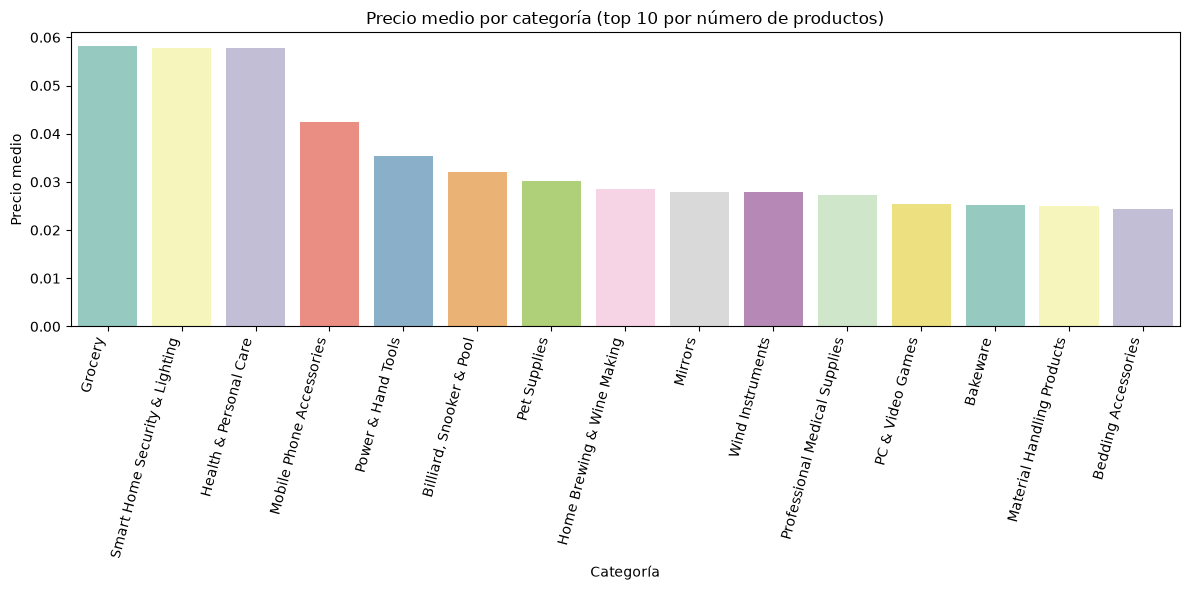

In [30]:
plt.figure(figsize=(12, 6))
sns.barplot(x=frequency_table.index, y=frequency_table.values, palette="Set3");
plt.title("Precio medio por categoría (top 10 por número de productos)")
plt.xlabel("Categoría")
plt.ylabel("Precio medio")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


In [31]:
mean_prices = df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)

print(mean_prices.head(10))

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64


PARTE 3

EJERCICIO 1

In [32]:
from scipy.stats import pearsonr, spearmanr
correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])
print(f"Correlación de Pearson: {correlation:.4f}")

r, p_value = pearsonr(df_no_outliers["price"], df_no_outliers["stars"])
print(f"Pearson r: {r:.4f} | p-value: {p_value:.4g}")

rho, p_spearman = spearmanr(df_no_outliers["price"], df_no_outliers["stars"])
print(f"Spearman rho: {rho:.4f} | p-value: {p_spearman:.4g}")

Correlación de Pearson: -0.0777
Pearson r: -0.0777 | p-value: 0
Spearman rho: -0.0668 | p-value: 0
